# Market microstructure with TradeMatch

This notebook drives TradeMatch's C++ engine from Python. It runs the engine's agent-based market and measures it the
way empirical studies measure real markets: the bid-ask spread, how the order book predicts the next price move, how
order flow persists, and how trades move prices. Then it replays a real day of NASDAQ data through the same engine and
repeats the measurements.

The simulated sections take seconds and need nothing but the package (`pip install ".[notebook]"` from the
repository root). The last section needs NASDAQ's ITCH file for 30 December 2019, a free 390 MB download.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

import tradematch as tm

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})
SIMULATED, REAL, FAIR = "#2563eb", "#ea580c", "#16a34a"

SIMULATED_TRADE_COLUMNS = ["time", "symbol", "price", "quantity", "aggressor", "buy_order_id", "sell_order_id"]
FEED_TRADE_COLUMNS = ["time", "symbol", "price", "quantity", "aggressor"]
QUOTE_COLUMNS = ["time", "symbol", "phase", "bid", "bid_size", "ask", "ask_size", "fair"]

## 1. A simulated session

The simulator's market has four kinds of agents. **Market makers** quote both sides around a fair value that only they
can see. **Noise traders** send passive, marketable, and market orders on either side at random. **Momentum traders**
chase the trend of the price's moving averages, and a **whale** works large iceberg orders and parks stop orders. The
fair value is a random walk with occasional news jumps.

One trading day here is a 4-second opening auction, 30 minutes of continuous trading, and a 4-second closing auction.
Every 10 ms step records the top of the book, and every trade is recorded with the side that took liquidity. Prices
are integer ticks of one cent, starting at $100.00. A seed always replays the same market.

In [2]:
started = time.perf_counter()
simulator = tm.MarketSimulator(seed=42, symbols=["ACME"], continuous_seconds=1_800)
simulator.run_day()
elapsed = time.perf_counter() - started

trades = pd.DataFrame(simulator.take_trades(), columns=SIMULATED_TRADE_COLUMNS)
quotes = pd.DataFrame(simulator.take_quotes(), columns=QUOTE_COLUMNS)
continuous = quotes[quotes.phase == "CONTINUOUS"].dropna(subset=["bid", "ask"]).copy()
continuous["mid"] = (continuous.bid + continuous.ask) / 2
continuous["spread"] = continuous.ask - continuous.bid
OPEN = 4 * 10**9  # the opening auction ends 4 s into the day

stats = simulator.stats
print(f"{stats['requests']:,} requests and {stats['trades']:,} trades in {elapsed:.2f} s of wall time")
print(f"{len(quotes):,} quotes recorded; {stats['auctions']} auctions; {stats['stops_triggered']} stops triggered")
trades.groupby("aggressor").quantity.agg(trades="count", shares="sum").rename(
    index={"B": "buyer-initiated", "S": "seller-initiated", "X": "auctions"})

765,217 requests and 81,495 trades in 0.12 s of wall time
180,800 quotes recorded; 2 auctions; 115 stops triggered


,trades,shares
aggressor,,
buyer-initiated,44025,8289000
seller-initiated,37349,7079700
auctions,121,20800


## 2. The session at a glance

The market makers anchor their quotes to the hidden fair value, so the price follows it, with a lag and with noise.
Buyer- and seller-initiated volume alternate in waves, and the spread is almost always one or two ticks.

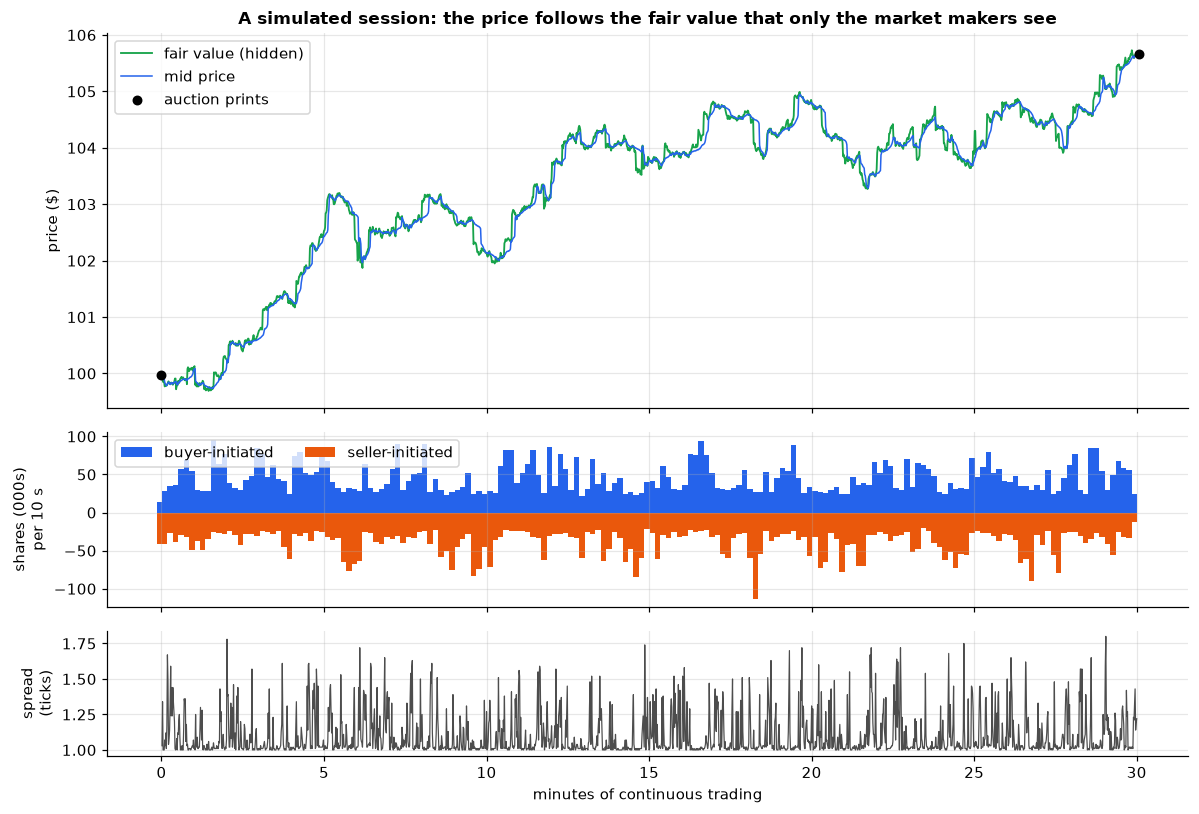

In [3]:
def minutes(times):
    return (np.asarray(times) - OPEN) / 60e9


per_second = continuous.groupby(continuous.time // 10**9).agg(
    time=("time", "last"), mid=("mid", "last"), fair=("fair", "last"), spread=("spread", "mean"))
continuous_trades = trades[trades.aggressor != "X"]
buckets = continuous_trades.groupby([continuous_trades.time // (10 * 10**9), "aggressor"]).quantity.sum().unstack(fill_value=0)
auctions = trades[trades.aggressor == "X"].groupby("time").agg(price=("price", "first"), volume=("quantity", "sum"))

fig, (price_axis, volume_axis, spread_axis) = plt.subplots(
    3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.4, 1]})
price_axis.plot(minutes(per_second.time), per_second.fair / 100, color=FAIR, lw=1.2, label="fair value (hidden)")
price_axis.plot(minutes(per_second.time), per_second.mid / 100, color=SIMULATED, lw=1, label="mid price")
price_axis.scatter(minutes(auctions.index), auctions.price / 100, color="black", zorder=3, s=30, label="auction prints")
price_axis.set_ylabel("price ($)")
price_axis.set_title("A simulated session: the price follows the fair value that only the market makers see")
price_axis.legend(loc="upper left")

bar_minutes = minutes(buckets.index * 10 * 10**9)
volume_axis.bar(bar_minutes, buckets.get("B", 0) / 1_000, width=10 / 60, color=SIMULATED, label="buyer-initiated")
volume_axis.bar(bar_minutes, -buckets.get("S", 0) / 1_000, width=10 / 60, color=REAL, label="seller-initiated")
volume_axis.set_ylabel("shares (000s)\nper 10 s")
volume_axis.legend(loc="upper left", ncols=2)

spread_axis.plot(minutes(per_second.time), per_second.spread, color="0.3", lw=0.8)
spread_axis.set_ylabel("spread\n(ticks)")
spread_axis.set_xlabel("minutes of continuous trading")
plt.tight_layout()
plt.show()

## 3. Market makers make the market

A simulator can run experiments that history can't. Here the same market runs with 0 to 16 market makers, over five
seeds each. Without them, the spread is set by whatever the noise traders leave in the book. The first maker does most
of the work: the spread collapses to about a tick and the price calms down. More makers mostly add depth at the touch.

30 simulated sessions of 10 minutes in 2.5 s


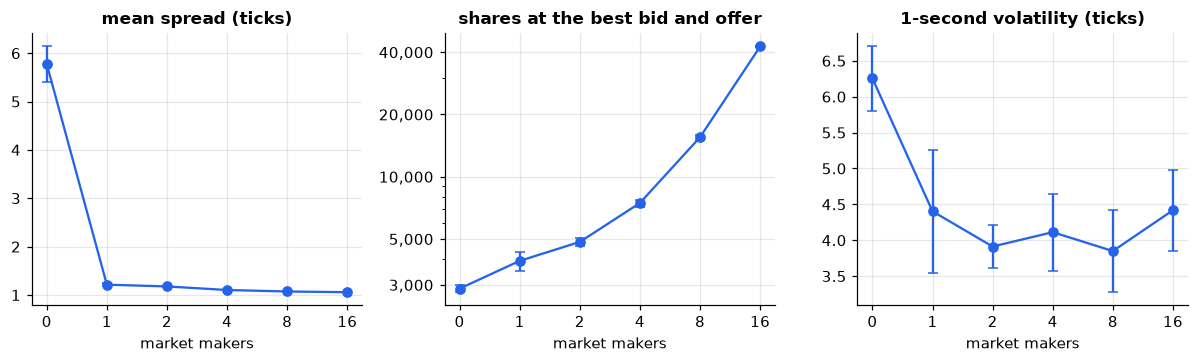

,spread,depth,volatility
market_makers,,,
0,5.78,2879.42,6.26
1,1.21,3920.67,4.40
2,1.18,4840.78,3.91
4,1.10,7467.76,4.11
8,1.07,15530.86,3.85
16,1.06,42633.03,4.42


In [4]:
def session_measures(market_makers, seed):
    market = tm.MarketSimulator(seed=seed, market_makers=market_makers, continuous_seconds=600)
    market.run_day()
    rows = pd.DataFrame(market.take_quotes(), columns=QUOTE_COLUMNS)
    rows = rows[rows.phase == "CONTINUOUS"].dropna(subset=["bid", "ask"])
    mid = (rows.bid + rows.ask) / 2
    return {
        "market_makers": market_makers,
        "spread": (rows.ask - rows.bid).mean(),
        "depth": (rows.bid_size + rows.ask_size).mean(),
        "volatility": mid.iloc[::100].diff().std(),  # of one-second mid-price changes, in ticks
    }


started = time.perf_counter()
experiment = pd.DataFrame(
    [session_measures(makers, seed) for makers in [0, 1, 2, 4, 8, 16] for seed in range(5)])
print(f"30 simulated sessions of 10 minutes in {time.perf_counter() - started:.1f} s")
summary = experiment.groupby("market_makers").agg(["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for axis, (column, label) in zip(axes, [
        ("spread", "mean spread (ticks)"),
        ("depth", "shares at the best bid and offer"),
        ("volatility", "1-second volatility (ticks)")]):
    positions = np.arange(len(summary))
    axis.errorbar(positions, summary[column]["mean"], yerr=summary[column]["std"], color=SIMULATED, marker="o", capsize=3)
    axis.set_xticks(positions, summary.index)
    axis.set_xlabel("market makers")
    axis.set_title(label)
axes[1].set_yscale("log")
axes[1].set_yticks([3_000, 5_000, 10_000, 20_000, 40_000])
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_minor_formatter(ticker.NullFormatter())
plt.tight_layout()
plt.show()
summary.xs("mean", axis=1, level=1).round(2)

## 4. The queue predicts the next move

With a one-tick spread, the price moves when one side's queue at the touch runs out. So the queue imbalance

$$I = \frac{\text{bid size} - \text{ask size}}{\text{bid size} + \text{ask size}}$$

should predict the direction of the next change in the mid price. When the bid queue is much longer than the offer
queue ($I$ near 1), the offer is likely to go first and the price to tick up. This is one of the most robust patterns
in real order books.

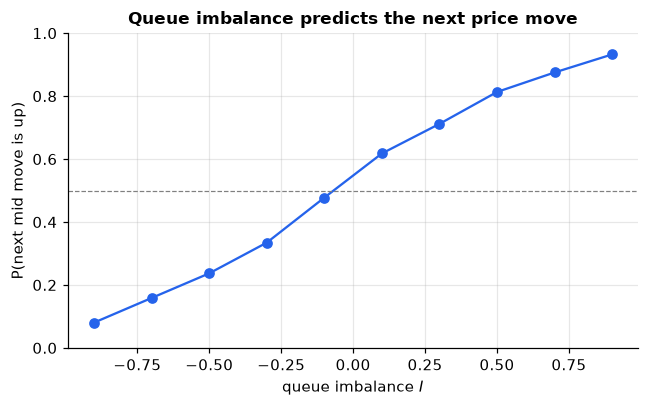

In [5]:
IMBALANCE_BINS = np.linspace(-1, 1, 11)


def next_move_up(quote_rows):
    # For each sample, whether the next change in the mid price is upward, by queue imbalance at the sample.
    rows = quote_rows.dropna(subset=["bid", "ask"])
    mid = (rows.bid + rows.ask) / 2
    imbalance = (rows.bid_size - rows.ask_size) / (rows.bid_size + rows.ask_size)
    changed = mid.ne(mid.shift())
    next_mid = mid.where(changed).shift(-1).bfill()  # the mid after the next change
    known = next_mid.notna()
    up = (next_mid > mid)[known]
    bins = pd.cut(imbalance[known], IMBALANCE_BINS, include_lowest=True)
    result = up.groupby(bins, observed=True).mean()
    result.index = [interval.mid for interval in result.index]
    return result


simulated_up = next_move_up(continuous)
fig, axis = plt.subplots(figsize=(6, 3.8))
axis.plot(simulated_up.index, simulated_up.values, color=SIMULATED, marker="o", label="simulated")
axis.axhline(0.5, color="0.5", lw=0.8, ls="--")
axis.set_xlabel("queue imbalance $I$")
axis.set_ylabel("P(next mid move is up)")
axis.set_title("Queue imbalance predicts the next price move")
axis.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 5. Order flow is persistent

In real markets, a buy tends to follow a buy: the signs of trades are correlated far into the future. Here each
aggressive order counts once, however many resting orders it fills, and its sign is +1 for a buy and -1 for a sell.
The simulator's tape names the orders behind every trade; a public feed doesn't, but there an aggressive order's fills
share a single nanosecond timestamp.

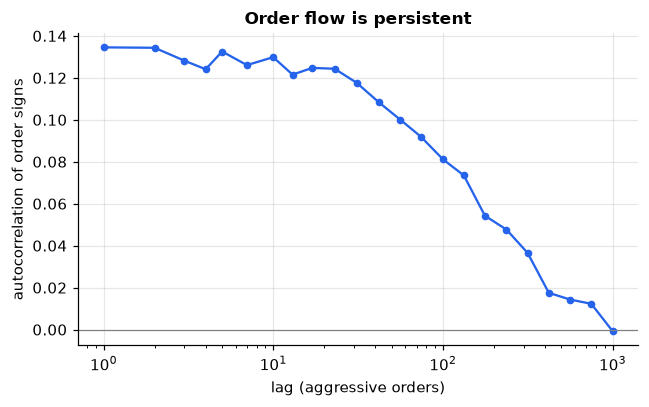

In [6]:
LAGS = np.unique(np.logspace(0, 3, 25).astype(int))


def aggressive_orders(trade_rows):
    rows = trade_rows[trade_rows.aggressor.isin(["B", "S"])]
    if "buy_order_id" in rows:
        taker = pd.Series(np.where(rows.aggressor == "B", rows.buy_order_id, rows.sell_order_id), index=rows.index)
        first_fill = taker.ne(taker.shift())
    else:
        first_fill = rows.time.ne(rows.time.shift()) | rows.aggressor.ne(rows.aggressor.shift())
    orders = rows[first_fill].copy()
    orders["sign"] = np.where(orders.aggressor == "B", 1.0, -1.0)
    return orders


def sign_autocorrelation(trade_rows, lags=LAGS):
    signs = aggressive_orders(trade_rows).sign.to_numpy()
    signs = signs - signs.mean()
    variance = np.mean(signs * signs)
    return pd.Series([np.mean(signs[:-lag] * signs[lag:]) / variance for lag in lags], index=lags)


simulated_acf = sign_autocorrelation(trades)
fig, axis = plt.subplots(figsize=(6, 3.8))
axis.semilogx(simulated_acf.index, simulated_acf.values, color=SIMULATED, marker="o", ms=4, label="simulated")
axis.axhline(0, color="0.5", lw=0.8)
axis.set_xlabel("lag (aggressive orders)")
axis.set_ylabel("autocorrelation of order signs")
axis.set_title("Order flow is persistent")
plt.tight_layout()
plt.show()

## 6. Trades carry information

The response function $R(\tau) = \mathbb{E}[\varepsilon_n \, (m_{t_n+\tau} - m_{t_n^-})]$ is the average move of the mid
price $m$ in the direction of an aggressive order $\varepsilon_n$, from just before it to $\tau$ later. In the simulator
it keeps growing for seconds after the trade. The reason is in the data: most orders trade toward the hidden fair value
(they buy when the price is below it), so a trade tells the market which way the price is heading.

67% of aggressive orders trade toward the fair value


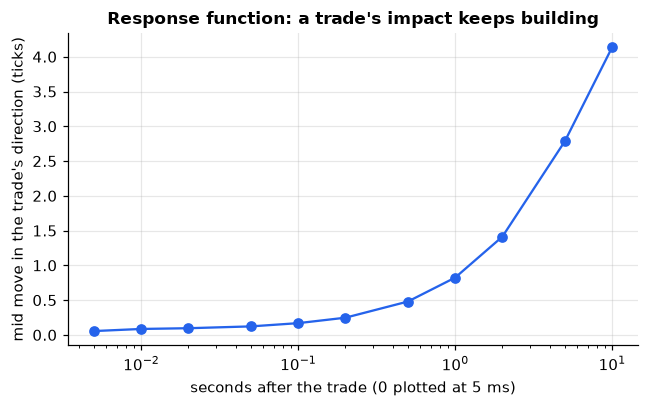

In [7]:
STEP = 10**7  # one 10 ms step
orders = aggressive_orders(trades[trades.time > OPEN])
mid_at = continuous.set_index("time").mid
fair_at = continuous.set_index("time").fair
before = mid_at.reindex(orders.time - STEP).to_numpy()

taus = np.array([0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1_000])
response = []
for tau in taus:
    after = mid_at.reindex(orders.time + tau * STEP).to_numpy()
    known = ~np.isnan(before) & ~np.isnan(after)
    response.append(np.mean(orders.sign.to_numpy()[known] * (after[known] - before[known])))

gap = fair_at.reindex(orders.time - STEP).to_numpy() - before
known = ~np.isnan(gap) & (gap != 0)
toward_fair = np.mean(np.sign(gap[known]) == orders.sign.to_numpy()[known])
print(f"{toward_fair:.0%} of aggressive orders trade toward the fair value")

fig, axis = plt.subplots(figsize=(6, 3.8))
axis.semilogx(np.maximum(taus, 0.5) * STEP / 1e9, response, color=SIMULATED, marker="o")
axis.set_xlabel("seconds after the trade (0 plotted at 5 ms)")
axis.set_ylabel("mid move in the trade's direction (ticks)")
axis.set_title("Response function: a trade's impact keeps building")
plt.tight_layout()
plt.show()

## 7. A real day: NASDAQ BX, 30 December 2019

NASDAQ publishes full-depth TotalView-ITCH 5.0 files, every order added, executed, cancelled, and replaced, at
[emi.nasdaq.com/ITCH](https://emi.nasdaq.com/ITCH/). `ItchReplica` rebuilds every stock's order book from such a file,
order by order, in TradeMatch's own books, and records the trades of the stocks it watches with their aggressors.

To run this section, download `Nasdaq BX ITCH/20191230.BX_ITCH_50.gz`, unpack it into `notebooks/data/`, or point the
`TRADEMATCH_ITCH_FILE` environment variable at it. The stock here is GDX, the VanEck gold miners ETF, which had more
trades on BX that day than any other stock. Note that this is one exchange's book, not the consolidated market.

In [8]:
ITCH_FILE = Path(os.environ.get("TRADEMATCH_ITCH_FILE", "data/20191230.BX_ITCH_50"))
HAVE_ITCH = ITCH_FILE.exists()
STOCK, SAMPLE_EVERY = "GDX", 100_000_000  # top-of-book samples every 100 ms

if HAVE_ITCH:
    started = time.perf_counter()
    replica = tm.ItchReplica(ITCH_FILE, watch=[STOCK])
    replica.advance("9:30")
    replica.take_trades()  # pre-market trades
    samples = []
    for now in range(tm.time_of_day("9:30") + SAMPLE_EVERY, tm.time_of_day("16:00") + 1, SAMPLE_EVERY):
        replica.advance(now)
        samples.append((now,) + replica.top_of_book(STOCK))
    real_trades = pd.DataFrame(replica.take_trades(), columns=FEED_TRADE_COLUMNS)
    replica.advance()  # the rest of the day
    elapsed = time.perf_counter() - started

    real_quotes = pd.DataFrame(samples, columns=["time", "bid", "bid_size", "ask", "ask_size"])
    for column in ["bid", "ask"]:
        real_quotes[column] /= 100  # ITCH prices are in 1/10,000 of a dollar; these are cents, one tick
    real_trades["price"] /= 100
    real_stats = replica.stats
    print(f"{real_stats['messages']:,} messages for {len(replica.symbols):,} stocks replayed in {elapsed:.1f} s, "
          f"with {real_stats['anomalies']} anomalies and {real_stats['invalid_messages']} invalid messages")
    print(f"{STOCK}: {len(real_trades):,} trades and {len(real_quotes):,} top-of-book samples in regular hours")
else:
    print(f"{ITCH_FILE} not found: download it to run this section (see above)")

29,156,757 messages for 8,906 stocks replayed in 3.6 s, with 0 anomalies and 0 invalid messages
GDX: 25,822 trades and 234,000 top-of-book samples in regular hours


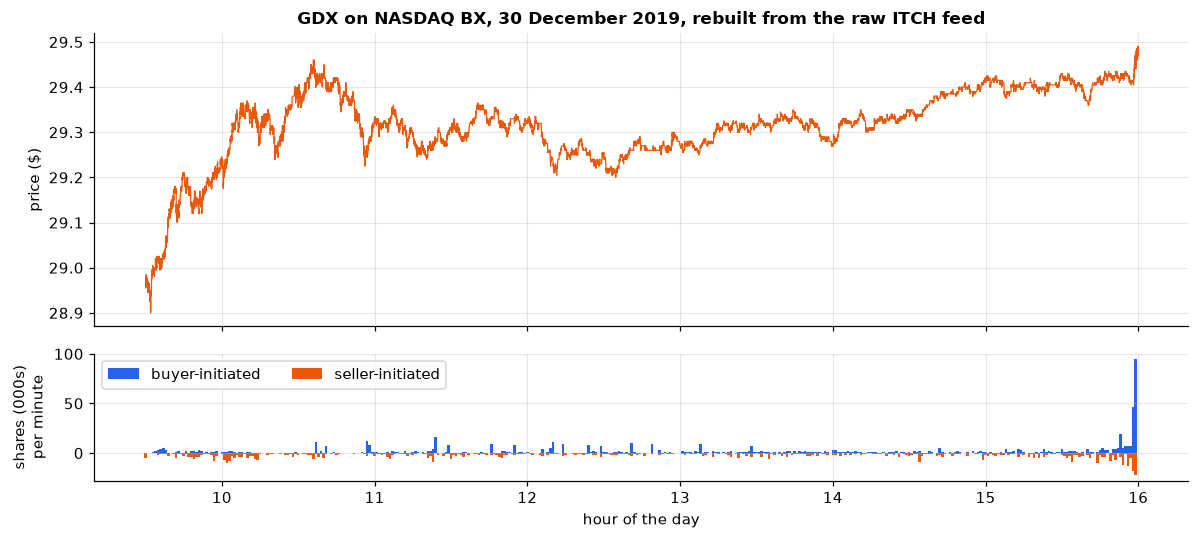

In [9]:
if HAVE_ITCH:
    real = real_quotes.dropna(subset=["bid", "ask"]).copy()
    real["mid"] = (real.bid + real.ask) / 2
    # Just after the open, the book is briefly more than a dollar wide, and its mid says little.
    tight = real[real.ask - real.bid <= 10]
    hours = lambda times: np.asarray(times) / 3.6e12

    fig, (price_axis, volume_axis) = plt.subplots(
        2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    price_axis.plot(hours(tight.time), tight.mid / 100, color=REAL, lw=0.8, label="BX mid price")
    price_axis.set_ylabel("price ($)")
    price_axis.set_title(f"{STOCK} on NASDAQ BX, 30 December 2019, rebuilt from the raw ITCH feed")
    minute = 60 * 10**9
    by_minute = real_trades.groupby([real_trades.time // minute * minute, "aggressor"]).quantity.sum().unstack(fill_value=0)
    volume_axis.bar(hours(by_minute.index), by_minute.get("B", 0) / 1_000, width=1 / 60, color=SIMULATED, label="buyer-initiated")
    volume_axis.bar(hours(by_minute.index), -by_minute.get("S", 0) / 1_000, width=1 / 60, color=REAL, label="seller-initiated")
    volume_axis.set_ylabel("shares (000s)\nper minute")
    volume_axis.set_xlabel("hour of the day")
    volume_axis.legend(loc="upper left", ncols=2)
    plt.tight_layout()
    plt.show()

### The same measurements, simulated and real

The spread, the queue-imbalance predictor, and order-flow persistence, computed by the same functions on both markets.

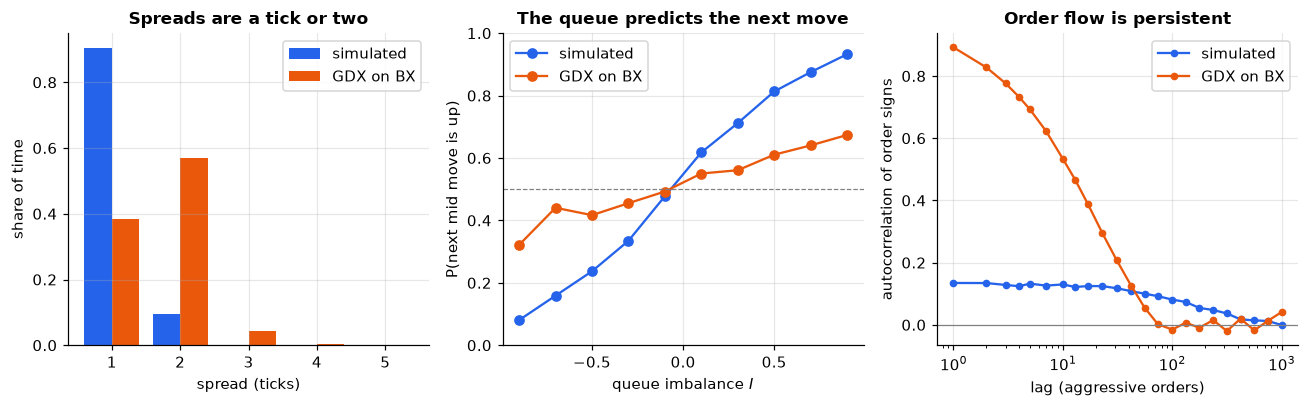

median trade: 200 shares simulated, 16 shares for GDX


In [10]:
if HAVE_ITCH:
    real_up = next_move_up(real_quotes)
    real_acf = sign_autocorrelation(real_trades)
    spreads = pd.DataFrame({
        "simulated": continuous.spread.round().value_counts(normalize=True),
        STOCK: (real.ask - real.bid).round().value_counts(normalize=True),
    }).fillna(0).sort_index().loc[1:5]

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    positions = np.arange(len(spreads))
    axes[0].bar(positions - 0.2, spreads["simulated"], width=0.4, color=SIMULATED, label="simulated")
    axes[0].bar(positions + 0.2, spreads[STOCK], width=0.4, color=REAL, label=f"{STOCK} on BX")
    axes[0].set_xticks(positions, spreads.index.astype(int))
    axes[0].set_xlabel("spread (ticks)")
    axes[0].set_ylabel("share of time")
    axes[0].set_title("Spreads are a tick or two")
    axes[0].legend()

    axes[1].plot(simulated_up.index, simulated_up.values, color=SIMULATED, marker="o", label="simulated")
    axes[1].plot(real_up.index, real_up.values, color=REAL, marker="o", label=f"{STOCK} on BX")
    axes[1].axhline(0.5, color="0.5", lw=0.8, ls="--")
    axes[1].set_ylim(0, 1)
    axes[1].set_xlabel("queue imbalance $I$")
    axes[1].set_ylabel("P(next mid move is up)")
    axes[1].set_title("The queue predicts the next move")
    axes[1].legend()

    axes[2].semilogx(simulated_acf.index, simulated_acf.values, color=SIMULATED, marker="o", ms=4, label="simulated")
    axes[2].semilogx(real_acf.index, real_acf.values, color=REAL, marker="o", ms=4, label=f"{STOCK} on BX")
    axes[2].axhline(0, color="0.5", lw=0.8)
    axes[2].set_xlabel("lag (aggressive orders)")
    axes[2].set_ylabel("autocorrelation of order signs")
    axes[2].set_title("Order flow is persistent")
    axes[2].legend()
    plt.tight_layout()
    plt.show()

    median_sizes = (trades[trades.aggressor != "X"].quantity.median(), real_trades.quantity.median())
    print(f"median trade: {median_sizes[0]:.0f} shares simulated, {median_sizes[1]:.0f} shares for {STOCK}")

Both markets show the textbook patterns, and the differences are instructive:

* **Spreads** are pinned near the one-cent tick in both. GDX spends more of its time at two ticks: BX is a smaller
  exchange, and one exchange's book can never be tighter than the best prices across all of them.
* **Queue imbalance** predicts the next move in both. The signal is sharper in the simulator, where the whole market
  is one book; on BX, part of the price formation happens on other exchanges.
* **Order flow** is far more persistent in real GDX at short lags, and the correlation fades within about fifty
  orders. That is the pattern usually attributed to algorithms slicing large orders into many small ones, and the median
  GDX trade is a fraction of the simulator's. None of the simulator's agents split their orders, which makes such an
  agent the obvious next one to add.

In [11]:
# The summary figure in the repository's README.
if HAVE_ITCH and Path("../docs/assets").is_dir():
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
    axes[0, 0].plot(minutes(per_second.time), per_second.fair / 100, color=FAIR, lw=1.2, label="fair value (hidden)")
    axes[0, 0].plot(minutes(per_second.time), per_second.mid / 100, color=SIMULATED, lw=1, label="mid price")
    axes[0, 0].set_xlabel("minutes of continuous trading")
    axes[0, 0].set_ylabel("price ($)")
    axes[0, 0].set_title("Simulated: the price tracks a hidden fair value")
    axes[0, 0].legend(loc="upper left")

    positions = np.arange(len(summary))
    axes[0, 1].errorbar(positions, summary["spread"]["mean"], yerr=summary["spread"]["std"], color=SIMULATED,
                        marker="o", capsize=3)
    axes[0, 1].set_xticks(positions, summary.index)
    axes[0, 1].set_xlabel("market makers")
    axes[0, 1].set_ylabel("mean spread (ticks)")
    axes[0, 1].set_title("Simulated: market makers tighten the spread")

    axes[1, 0].plot(simulated_up.index, simulated_up.values, color=SIMULATED, marker="o", label="simulated")
    axes[1, 0].plot(real_up.index, real_up.values, color=REAL, marker="o", label=f"{STOCK} on NASDAQ BX")
    axes[1, 0].axhline(0.5, color="0.5", lw=0.8, ls="--")
    axes[1, 0].set_ylim(0, 1)
    axes[1, 0].set_xlabel("queue imbalance $I$")
    axes[1, 0].set_ylabel("P(next mid move is up)")
    axes[1, 0].set_title("Queue imbalance predicts the next move")
    axes[1, 0].legend()

    axes[1, 1].semilogx(simulated_acf.index, simulated_acf.values, color=SIMULATED, marker="o", ms=4, label="simulated")
    axes[1, 1].semilogx(real_acf.index, real_acf.values, color=REAL, marker="o", ms=4, label=f"{STOCK} on NASDAQ BX")
    axes[1, 1].axhline(0, color="0.5", lw=0.8)
    axes[1, 1].set_xlabel("lag (aggressive orders)")
    axes[1, 1].set_ylabel("autocorrelation of order signs")
    axes[1, 1].set_title("Order flow is persistent")
    axes[1, 1].legend()
    plt.tight_layout()
    fig.savefig("../docs/assets/microstructure.png", dpi=110)
    plt.close(fig)
    print("saved docs/assets/microstructure.png")

saved docs/assets/microstructure.png
